# RAS 2026 — Variable-agent data harvesting

This notebook produces the compact set of analyses selected for the paper. It treats the MLflow runs as experimental conditions rather than as a chronological development log.

The three research questions are:

1. Does inverse-cardinality agent-count sampling balance replay experience and improve performance for smaller teams?
2. Is training-time exposure to agent deaths required for robustness to deaths at evaluation time?
3. What does the flex encoder change relative to a conventional MLP in sample efficiency, final success, and completion time?

The paper uses four result panels from this notebook: the training curve (Figure 2), the two final-policy panels (Figure 3), and the team-size sampling comparison (Figure 4). The failure-exposure results appear in the paper as Tables 1 and 2; the notebook additionally retains an expanded diagnostic plot and numerical summaries.

## Setup and reproducibility

Runs are resolved by their unique names in the `death` MLflow experiment through `data_harvesting.analysis.ExperimentRun`. Final-policy evaluations use deterministic episode seeds so the compared policies receive the same scenario sequence.

Periodic training evaluations contain 100 randomly generated episodes every 250,000 collected transitions. Their episode seeds were not fixed during training, so they are appropriate for learning-curve trends but not paired checkpoint comparisons.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from data_harvesting.analysis import ExperimentRun

TRACKING_URI = "http://localhost:5000"
EXPERIMENT_NAME = "death"
SAMPLING_EVAL_SEED = 20260819
ARCHITECTURE_EVAL_SEED = 20260827
FINAL_EVAL_EPISODES = 2_000
DEATH_EVAL_SEED = 20260823
DEATH_PROBABILITIES = np.linspace(0.0, 1.0, num=10, endpoint=True).tolist()
POPULATION_TRIALS = list(range(1, 21))

sns.set_theme(context="paper", style="whitegrid", font_scale=1.0)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
})

In [2]:
RUNS = {
    name: ExperimentRun.from_name(EXPERIMENT_NAME, name, tracking_uri=TRACKING_URI)
    for name in ("3_refactor", "4_proportional", "5_deathless", "6_mlp", "7_deathful", "8_bucketed", "9_fixed_5")
}

pd.DataFrame(
    [
        {"run": name, "run_id": run.run_id, "status": run.status}
        for name, run in RUNS.items()
    ]
)

,run,run_id,status
0,3_refactor,b061979ceea243e29004ade9fc564fff,FINISHED
1,4_proportional,97433115b8024391893e231420109904,FINISHED
2,5_deathless,a221353db7fc421b9a6b821061b9fd8d,FINISHED
3,6_mlp,338ec9a2f2ee4728a92215538cbbad87,FINISHED
4,7_deathful,f7d501ba49d24d8991c12fce437f82d5,FINISHED
5,8_bucketed,673dc243365849c3b7df0a1838620566,FINISHED
6,9_fixed_5,a7bc029daafe4c81b77887fd73ea19b3,FINISHED


In [3]:
LABELS = {
    "3_refactor": "Uniform sampling",
    "4_proportional": "Inverse sampling",
    "8_bucketed": "Bucketed sampling",
    "5_deathless": "Flex Encoder",
    "6_mlp": "MLP",
}

# Experiment 1 — Agent-count sampling ablation

**Research question.** Does sampling the initial number of agents with probability proportional to $1/n$ correct the weaker performance observed at low agent counts?

`3_refactor` and `4_proportional` use the same medium flex architecture, training budget, hyperparameters, and training death probability. The experimental change is the initial agent-count distribution: uniform sampling in `3_refactor` and inverse sampling in `4_proportional`.

`8_bucketed` also uses the same architecture, but samples according to a bucketed sampling strategy proposed by Alarcon et al. (2025)

Final policies are evaluated without deaths on the same seeded episodes. Success is grouped by the initial number of agents; sensor count remains randomized from one to 36. Seaborn estimates 95% confidence intervals from the episode-level results.

In [4]:
sampling_episodes = pd.concat(
    [
        RUNS[run_name].final_model().evaluate(
            FINAL_EVAL_EPISODES,
            seed=SAMPLING_EVAL_SEED,
                num_workers=4,
            config_overrides={"environment": {"agent_death_probability": 0.0}},
        ).assign(condition=LABELS[run_name])
        for run_name in ("3_refactor", "4_proportional", "8_bucketed")
    ],
    ignore_index=True,
)

In [5]:
proportional_ablation = sampling_episodes.assign(
    num_agents=lambda data: data["num_agents"].astype(int),
    success_percent=lambda data: data["all_collected"].astype(float) * 100,
)

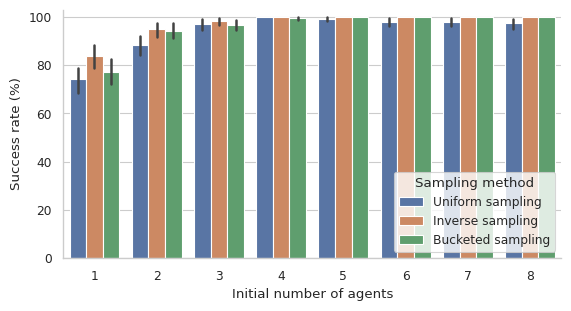

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 3.2))
sns.barplot(data=proportional_ablation, x="num_agents", y="success_percent", hue="condition", ax=ax)

ax.set(xlabel="Initial number of agents", ylabel="Success rate (%)", ylim=(0, 103))
ax.legend(loc="lower right", title="Sampling method")

fig.tight_layout()

In [7]:
one_agent_case = proportional_ablation.query("num_agents == 1").groupby("condition")["success_percent"].mean()
one_agent_case

condition
Bucketed sampling    77.327935
Inverse sampling     83.805668
Uniform sampling     74.089069
Name: success_percent, dtype: float64

In [8]:
all_case_summary = proportional_ablation.groupby("condition")["success_percent"].agg(["mean", "std"])
all_case_summary

,mean,std
condition,,
Bucketed sampling,96.1,19.364335
Inverse sampling,97.2,16.501398
Uniform sampling,94.2,23.380191


**Reading Figure 4.** Inverse-cardinality sampling outperforms uniform sampling by 3.0 percentage points on average. The largest gain is in the single-agent setting (9.7 percentage points), where the two sampling distributions differ most. Performance remains high at larger team sizes. These performance gains alone do not establish that replay experience was balanced; the following diagnostic measures active-agent transition representation in fresh collection under the final policies.


## 1A. Active-agent transition distribution under final policies

Load each final policy, collect exactly `TRANSITION_FRAMES` joint environment steps, and count active-agent contributions by the number of agents active when the action is taken. Rollouts automatically reset completed episodes. Each run's logged environment settings are preserved, including initial-team sampling, sensors, deaths, termination rules, and observation capacity; `make_env` handles legacy failure configuration.

The copied policies have frozen weights and run without gradients on one CPU thread, explicitly in **train mode** to match training collection (including dropout). Gaussian action noise stays at the logged final sigma. The full rollout is counted directly: if the current-state mask contains **A** active agents, that frame adds **A** to bucket **A**. This includes agents that fail at the end of the transition and excludes padding and already-dead slots. Initial team size is not used.

This measures fresh collection under the final policies, not historical training replay or bucketed replay's optimization exposure. Episode lengths and deaths affect the shares, so inverse-cardinality initial-team sampling need not yield exactly 12.5% per team size.

In [5]:
from copy import deepcopy

import torch
from torchrl.envs.utils import ExplorationType, set_exploration_type

from data_harvesting.actor import create_exploratory_actor
from data_harvesting.environment import make_env

TRANSITION_COLLECTION_SEED = 20260831
TRANSITION_FRAMES = 50_000
TRANSITION_CONDITIONS = {"3_refactor": "Uniform", "4_proportional": "Inverse-cardinality"}
torch.set_num_threads(1)  # Avoid thread overhead for single-frame CPU inference.


@torch.no_grad()
def collect_transition_rollout(run, frames):
    config = run.config
    actor = deepcopy(run.final_model().load()).cpu().requires_grad_(False)
    policy, noise = create_exploratory_actor(actor, torch.device("cpu"), config)
    policy.train()
    noise.sigma.copy_(noise.sigma_end)
    env = make_env(config)
    try:
        env.set_seed(TRANSITION_COLLECTION_SEED)  # Seeds Python, NumPy, and PyTorch.
        with set_exploration_type(ExplorationType.RANDOM):
            return env.rollout(frames, policy, break_when_any_done=False, return_contiguous=True)
    finally:
        env.close()

In [6]:
transition_tables, transition_metadata = [], []
for run_name, condition in TRANSITION_CONDITIONS.items():
    run = RUNS[run_name]
    rollout = collect_transition_rollout(run, TRANSITION_FRAMES)
    active = rollout["agents", "mask"].sum(-1).numpy()  # Current-state mask, not next.
    joint_counts = np.bincount(active, minlength=9)[1:9]
    active_counts = np.bincount(active, weights=active, minlength=9)[1:9].astype(np.int64)
    percentages = 100 * active_counts / active_counts.sum()
    assert joint_counts.sum() == rollout.numel() == TRANSITION_FRAMES
    assert active_counts.sum() == active.sum()
    assert np.isclose(percentages.sum(), 100)
    transition_tables.append(pd.DataFrame({
        "run_name": run_name, "condition": condition,
        "active_team_size": np.arange(1, 9),
        "joint_frames": joint_counts,
        "active_agent_transitions": active_counts,
        "active_agent_percent": percentages,
    }))
    transition_metadata.append({
        "run_name": run_name, "run_id": run.run_id,
        "model_id": run.final_model().model_id,
        "joint_frames": rollout.numel(), "seed": TRANSITION_COLLECTION_SEED,
        "exploration_sigma": run.config["training"]["exploration_sigma_end"],
    })
    del rollout

transition_distribution = pd.concat(transition_tables, ignore_index=True)
display(pd.DataFrame(transition_metadata))
display(transition_distribution)

,run_name,run_id,model_id,joint_frames,seed,exploration_sigma
0,3_refactor,b061979ceea243e29004ade9fc564fff,m-dc34b0782213443caca653ca783e0825,50000,20260831,0.1
1,4_proportional,97433115b8024391893e231420109904,m-3875de69df2e47c0bb080f64b7565524,50000,20260831,0.1


,run_name,condition,active_team_size,joint_frames,active_agent_transitions,active_agent_percent
0,3_refactor,Uniform,1,10996,10996,5.722464
1,3_refactor,Uniform,2,8037,16074,8.365122
2,3_refactor,Uniform,3,6402,19206,9.995056
3,3_refactor,Uniform,4,4493,17972,9.352866
4,3_refactor,Uniform,5,5661,28305,14.730296
5,3_refactor,Uniform,6,5720,34320,17.860581
6,3_refactor,Uniform,7,4246,29722,15.467721
7,3_refactor,Uniform,8,4445,35560,18.505894
8,4_proportional,Inverse-cardinality,1,23464,23464,19.016744
9,4_proportional,Inverse-cardinality,2,9653,19306,15.646832


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before

INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO 

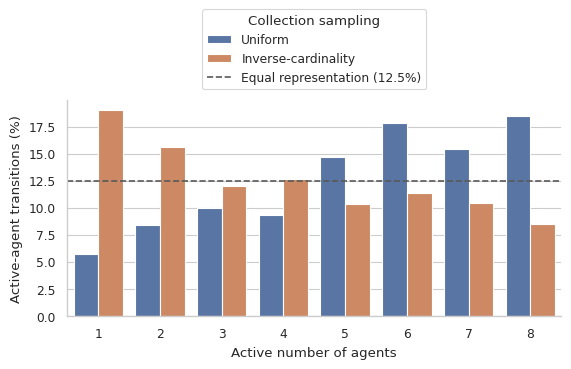

In [7]:
fig, ax = plt.subplots(figsize=(5.8, 3.8))
sns.barplot(
    data=transition_distribution, x="active_team_size", y="active_agent_percent",
    hue="condition", order=range(1, 9),
    hue_order=list(TRANSITION_CONDITIONS.values()), errorbar=None, ax=ax,
)
ax.axhline(12.5, color="0.35", linestyle="--", linewidth=1.2, label="Equal representation (12.5%)")
ax.set(xlabel="Active number of agents", ylabel="Active-agent transitions (%)", ylim=(0, None))
ax.legend(title="Collection sampling", loc="lower center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
plt.show()

**Reading the transition diagnostic.** Each bucket A counts A contributions per environment step with A currently active agents. The table and chart show these contributions as percentages of each policy's total. Equal joint-frame budgets can produce different totals of active-agent contributions. Compare the bars with the 12.5% reference; episode lengths and deaths affect representation, and performance gains in Figure 4 alone do not establish balanced replay experience.

In [8]:
uniform_transition_distribution = transition_distribution.query("condition == 'Uniform'")
inverse_transition_distribution = transition_distribution.query("condition == 'Inverse-cardinality'")

rmse_uniform = np.sqrt(np.mean((uniform_transition_distribution["active_agent_percent"] - 12.5) ** 2))
rmse_inverse = np.sqrt(np.mean((inverse_transition_distribution["active_agent_percent"] - 12.5) ** 2))

print(f"RMSE for uniform sampling: {rmse_uniform:.4f}")
print(f"RMSE for inverse-cardinality sampling: {rmse_inverse:.4f}")

RMSE for uniform sampling: 4.4413
RMSE for inverse-cardinality sampling: 3.1356


# Experiment 2 — Is death exposure required during training?

**Research question.** Does training with stochastic agent deaths improve robustness when agents disappear during evaluation?

The three policies use the same flex architecture, inverse agent-count sampling, hyperparameters, and 25M-step budget. They differ in their training-time death probability: `5_deathless` uses $p=0$, `4_proportional` uses $p=0.0005$, and `7_deathful` uses $p=0.002$. Each policy is evaluated over the same stochastic-death grid. The paper reports the $p \in \{0, 0.0005, 0.002\}$ subset in Tables 1 and 2; the notebook's plot and summaries retain four additional evaluation probabilities as a robustness diagnostic.

The comparison includes episodes with at least two initial agents. One-agent episodes are excluded because `prevent_last_agent_death` makes them deathless by construction.

In [ ]:
death_chunks = []

for probability in DEATH_PROBABILITIES:
    for run_name in ("4_proportional", "5_deathless", "7_deathful"):
        episodes = RUNS[run_name].final_model().evaluate(
            FINAL_EVAL_EPISODES,
            seed=DEATH_EVAL_SEED,
                num_workers=4,
            config_overrides={"environment": {"death_scheduler": {"type": "stochastic", "probability": probability}}},
        ).assign(
            condition={"4_proportional": "p=0.0005", "5_deathless": "p=0", "7_deathful": "p=0.002"}[run_name],
            death_probability=probability,
        )
        death_chunks.append(episodes)

death_episodes = pd.concat(death_chunks, ignore_index=True)
death_relevant = (
    death_episodes.query("num_agents > 1")
    .assign(success_percent=lambda data: data["all_collected"].astype(float) * 100)
)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before

INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO 

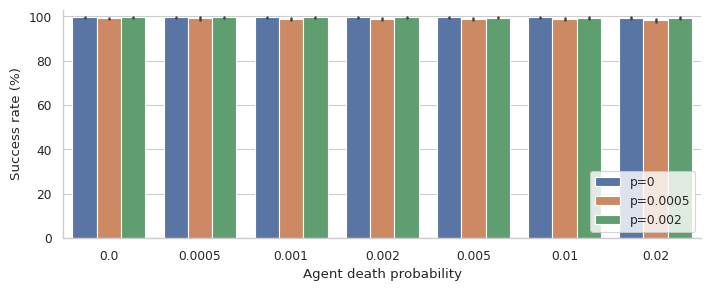

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
sns.lineplot(
    data=death_relevant,
    x="death_probability",
    y="success_percent",
    hue="condition",
    ax=ax,
    hue_order=["p=0", "p=0.0005", "p=0.002"]
)

ax.set(xlabel="Agent death probability", ylabel="Success rate (%)", ylim=(0, 103))
ax.legend(loc="lower right")

fig.tight_layout()
plt.show()

**Reading the diagnostic and Tables 1–2.** For a fixed training condition, changing the evaluation death probability has little effect on success or completion time over the three probabilities reported in the paper. Differences among training conditions are larger but nonmonotonic: training with $p=0.0005$ produces longer completion times, whereas $p=0.002$ is closer to training without deaths. The results therefore provide no evidence that greater failure exposure during training consistently improves performance. The probability controls stochastic exposure rather than guaranteeing a death in every episode, and longer episodes accumulate more opportunities for failure.

In [14]:
completion_time_by_death = (
    death_relevant.groupby(["death_probability", "condition"])[[ "completion_time"]]
    .agg("mean")
)

success_rate_by_death = (
    death_relevant.groupby(["death_probability", "condition"])[["success_percent"]]
    .agg("mean")
)

display(completion_time_by_death)
display(success_rate_by_death)

completion_time
death_probability condition                 
0.0000            p=0              31.224886
                  p=0.0005         36.175799
                  p=0.002          32.925799
0.0005            p=0              31.262557
                  p=0.0005         36.265982
                  p=0.002          32.950913
0.0010            p=0              31.059361
                  p=0.0005         36.586758
                  p=0.002          33.019406
0.0020            p=0              31.162100
                  p=0.0005         37.147260
                  p=0.002          33.176941
0.0050            p=0              32.044521
                  p=0.0005         37.613014
                  p=0.002          34.231735
0.0100            p=0              32.836758
                  p=0.0005         38.837900
                  p=0.002          35.598174
0.0200            p=0              35.827626
                  p=0.0005         44.119863
                  p=0.002          37.293379

success_percent
death_probability condition                 
0.0000            p=0              99.600457
                  p=0.0005         99.086758
                  p=0.002          99.600457
0.0005            p=0              99.600457
                  p=0.0005         99.086758
                  p=0.002          99.600457
0.0010            p=0              99.657534
                  p=0.0005         99.029680
                  p=0.002          99.600457
0.0020            p=0              99.657534
                  p=0.0005         98.915525
                  p=0.002          99.600457
0.0050            p=0              99.600457
                  p=0.0005         98.972603
                  p=0.002          99.486301
0.0100            p=0              99.600457
                  p=0.0005         98.972603
                  p=0.002          99.372146
0.0200            p=0              99.372146
                  p=0.0005         98.230594
                  p=0.002          99.372146

## Experiment 2A - Fixed population agents deal with loss

**Research question.** Is population variability what allows agents to adapt to deaths?

`5_deathless`is compared with `9_fixed_5` on evaluation scenarios with increasingly high death probabilities. 

In [ ]:
fixed_variable_chunks = []
for probability in DEATH_PROBABILITIES:
    for run_name in ("5_deathless", "9_fixed_5"):
        episodes = RUNS[run_name].final_model().evaluate(
            FINAL_EVAL_EPISODES,
            seed=DEATH_EVAL_SEED,
                num_workers=4,
            config_overrides={
                "environment": {
                    "death_scheduler": {"type": "stochastic", "probability": probability}
                },
                "min_num_agents": 5,
                "max_num_agents": 5
            },
        ).assign(
            condition={"5_deathless": "Variable Population", "9_fixed_5": "Fixed Population"}[run_name],
            death_probability=probability,
        )
        fixed_variable_chunks.append(episodes)

fixed_variable_episodes = pd.concat(fixed_variable_chunks, ignore_index=True)
fixed_variable_relevant = (
    fixed_variable_episodes.query("num_agents > 1")
    .assign(success_percent=lambda data: data["all_collected"].astype(float) * 100)
)

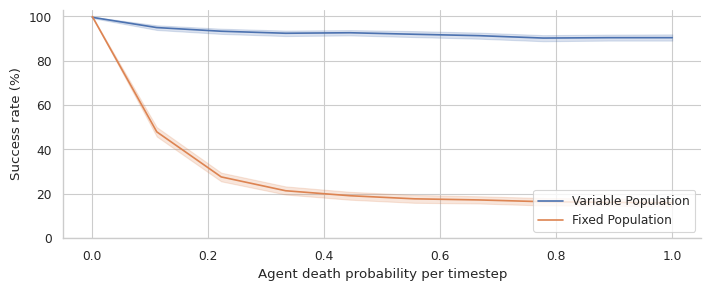

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
sns.lineplot(
  data=fixed_variable_relevant,
  x="death_probability",
  y="success_percent",
  hue="condition",
  errorbar=("ci", 95),
  hue_order=["Variable Population", "Fixed Population"],
  ax=ax
)
ax.set(xlabel="Agent death probability per timestep", ylabel="Success rate (%)", ylim=(0, 103))
ax.legend(loc="lower right")
fig.tight_layout()

In [18]:
fixed_variable_relevant

,source_run_id,source_run_name,model_name,model_id,model_step,model_kind,model_step_inferred,run_index,scenario_key,num_agents,...,episode_duration,completion_time,all_collected,num_collected,num_dead,cause,end_cause_label,condition,death_probability,success_percent
0,a221353db7fc421b9a6b821061b9fd8d,5_deathless,policy_model,m-683b355e218c42788bea90f4f3de2465,25000448,final,True,0,agents_4__sensors_2,4,...,3.0,8.0,1.0,2.0,0.0,2,ALL_COLLECTED,Variable Population,0.0,100.0
1,a221353db7fc421b9a6b821061b9fd8d,5_deathless,policy_model,m-683b355e218c42788bea90f4f3de2465,25000448,final,True,1,agents_3__sensors_8,3,...,9.0,20.0,1.0,8.0,0.0,2,ALL_COLLECTED,Variable Population,0.0,100.0
3,a221353db7fc421b9a6b821061b9fd8d,5_deathless,policy_model,m-683b355e218c42788bea90f4f3de2465,25000448,final,True,3,agents_6__sensors_33,6,...,17.0,36.0,1.0,33.0,0.0,2,ALL_COLLECTED,Variable Population,0.0,100.0
4,a221353db7fc421b9a6b821061b9fd8d,5_deathless,policy_model,m-683b355e218c42788bea90f4f3de2465,25000448,final,True,4,agents_4__sensors_17,4,...,13.0,28.0,1.0,17.0,0.0,2,ALL_COLLECTED,Variable Population,0.0,100.0
5,a221353db7fc421b9a6b821061b9fd8d,5_deathless,policy_model,m-683b355e218c42788bea90f4f3de2465,25000448,final,True,5,agents_6__sensors_30,6,...,24.0,50.0,1.0,30.0,0.0,2,ALL_COLLECTED,Variable Population,0.0,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,a7bc029daafe4c81b77887fd73ea19b3,9_fixed_5,policy_model,m-246b50a9528a4bcc93953b47f89fd716,25000448,final,True,1995,agents_5__sensors_34,5,...,26.0,500.0,0.0,11.0,4.0,3,STALLED,Fixed Population,1.0,0.0
39996,a7bc029daafe4c81b77887fd73ea19b3,9_fixed_5,policy_model,m-246b50a9528a4bcc93953b47f89fd716,25000448,final,True,1996,agents_5__sensors_3,5,...,14.0,30.0,1.0,3.0,4.0,2,ALL_COLLECTED,Fixed Population,1.0,100.0
39997,a7bc029daafe4c81b77887fd73ea19b3,9_fixed_5,policy_model,m-246b50a9528a4bcc93953b47f89fd716,25000448,final,True,1997,agents_5__sensors_4,5,...,19.0,40.0,1.0,4.0,4.0,2,ALL_COLLECTED,Fixed Population,1.0,100.0
39998,a7bc029daafe4c81b77887fd73ea19b3,9_fixed_5,policy_model,m-246b50a9528a4bcc93953b47f89fd716,25000448,final,True,1998,agents_5__sensors_18,5,...,20.0,500.0,0.0,5.0,4.0,3,STALLED,Fixed Population,1.0,0.0


# Experiment 3 - Flex encoder versus conventional MLP

**Research question.** What does the flex encoder change relative to a conventional MLP when both are trained across the same variable agent-count distribution without deaths?

`5_deathless` uses the medium flex encoder; `6_mlp` disables it and uses the conventional actor and critic networks. Both use inverse agent-count sampling and a 25M-step training budget. This experiment separates two outcomes: how quickly a useful policy is learned and how the final policies behave as the number of agents changes.

## 3A. Training sample efficiency

The periodic `eval/all_collected` histories are plotted against collected environment transitions as centered three-evaluation rolling means. Each underlying checkpoint evaluation contains 100 episodes with uniformly sampled agent counts, sensor counts, and sensor locations. This measures sample efficiency, not wall-clock efficiency.

In [15]:
learning_curves = []

for run_name in ("5_deathless", "6_mlp"):
    history = RUNS[run_name].metrics("eval/all_collected").rename(
        columns={"eval/all_collected": "success_rate"}
    )
    history["condition"] = LABELS[run_name]
    history["steps_millions"] = history["step"] / 1_000_000
    history["success_percent"] = 100 * history["success_rate"]
    history["rolling_success_percent"] = history["success_percent"].rolling(3, center=True, min_periods=1).mean()
    learning_curves.append(history)
learning_curves = pd.concat(learning_curves, ignore_index=True)
learning_curves.head()

,step,success_rate,condition,steps_millions,success_percent,rolling_success_percent
0,250368,0.70,Flex Encoder,0.250368,70.0,78.500000
1,500224,0.87,Flex Encoder,0.500224,87.0,77.333333
2,750080,0.75,Flex Encoder,0.750080,75.0,81.000000
3,1000448,0.81,Flex Encoder,1.000448,81.0,71.666667
4,1250304,0.59,Flex Encoder,1.250304,59.0,69.333333


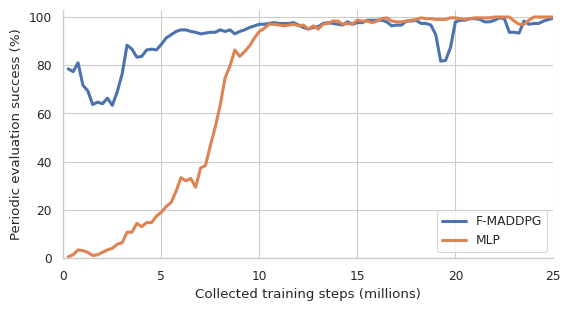

In [16]:
fig, ax = plt.subplots(figsize=(5.8, 3.2))

model_aliases = {
  "Flex Encoder": "F-MADDPG",
   "MLP": "MLP"
}

aliased_learning_curves = learning_curves.replace({"condition": model_aliases})

sns.lineplot(
    data=aliased_learning_curves, x="steps_millions", y="rolling_success_percent",
    hue="condition", hue_order=["F-MADDPG", "MLP"],
    estimator=None, linewidth=2.2, ax=ax, errorbar=("ci", 95)
)
ax.set(xlabel="Collected training steps (millions)", ylabel="Periodic evaluation success (%)", xlim=(0, 25), ylim=(0, 103))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

In [17]:
def first_sustained_step(frame, threshold, evaluations=3):
    values = frame.sort_values("step")["success_rate"].to_numpy()
    steps = frame.sort_values("step")["step"].to_numpy()
    for index in range(len(values) - evaluations + 1):
        if np.all(values[index:index + evaluations] >= threshold):
            return steps[index]
    return np.nan

milestones = pd.DataFrame(
    [
        {
            "condition": condition,
            "threshold": threshold,
            "sustained_step": first_sustained_step(
                learning_curves.query("condition == @condition"), threshold
            ),
        }
        for condition in ("Flex Encoder", "MLP")
        for threshold in (0.50, 0.80, 0.90, 0.95)
    ]
)
milestones["steps_millions"] = milestones["sustained_step"] / 1_000_000
milestones.pivot(index="threshold", columns="condition", values="steps_millions")

condition,Flex Encoder,MLP
threshold,,
0.50,0.250368,7.750144
0.80,3.000320,8.500224
0.90,5.250048,9.750016
0.95,9.250304,10.250240


**Reading Figure 2.** Both models approach 100% success by 25 million steps, but F-MADDPG reaches a sustained 90% success rate after approximately 5.3 million steps, compared with 9.8 million steps for the MLP baseline. This supports the paper's sample-efficiency claim. The comparison uses one training run per architecture, so it does not estimate training-seed variance.

## 3B. Final performance as agent count changes

The final policies are evaluated without deaths on the same 2,000 seeded episodes. Figure 3a reports success by initial team size with 95% confidence intervals. Figure 3b reports mean completion time—the timestep at which the final sensor is visited—for paired episodes completed successfully by both policies, preventing unsuccessful episodes whose completion time is capped at the horizon from distorting the comparison. The notebook keeps the panels separate for composition as subfigures in LaTeX.

In [18]:
architecture_chunks = []
architecture_overrides = {
    "5_deathless": {"environment": {"agent_death_probability": 0.0}},
    "6_mlp": {"environment": {"death_scheduler": {"type": "stochastic", "probability": 0.0}}},
}
for run_name in ("5_deathless", "6_mlp"):
    architecture_chunks.append(
        RUNS[run_name].final_model().evaluate(
            FINAL_EVAL_EPISODES,
            seed=ARCHITECTURE_EVAL_SEED,
                num_workers=4,
            config_overrides=architecture_overrides[run_name],
        ).assign(condition=LABELS[run_name])
    )
architecture_episodes = pd.concat(architecture_chunks, ignore_index=True).assign(
    num_agents=lambda data: data["num_agents"].astype(int),
    success_percent=lambda data: data["all_collected"].astype(float) * 100,
)

In [19]:
flex_episodes = architecture_episodes.query("condition == 'Flex Encoder'")[
    ["run_index", "num_agents", "num_sensors", "all_collected", "completion_time"]
].rename(columns={"all_collected": "flex_success", "completion_time": "flex_time"})
mlp_episodes = architecture_episodes.query("condition == 'MLP'")[
    ["run_index", "num_agents", "num_sensors", "all_collected", "completion_time"]
].rename(columns={"num_agents": "mlp_agents", "num_sensors": "mlp_sensors", "all_collected": "mlp_success", "completion_time": "mlp_time"})
paired = flex_episodes.merge(mlp_episodes, on="run_index", validate="one_to_one")
assert (paired["num_agents"] == paired["mlp_agents"]).all()
assert (paired["num_sensors"] == paired["mlp_sensors"]).all()
paired_successes = paired.query("flex_success == 1 and mlp_success == 1")
completion_episodes = paired_successes.melt(
    id_vars=["run_index", "num_agents"],
    value_vars=["flex_time", "mlp_time"],
    var_name="condition",
    value_name="completion_time",
).replace({"condition": {"flex_time": "F-MADDPG", "mlp_time": "MLP"}})

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before

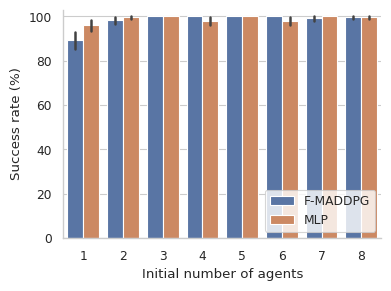

In [20]:
fig, ax = plt.subplots(figsize=(4.0, 3.0))
renamed_architecture_episodes = architecture_episodes.replace({"condition": {"Flex Encoder": "F-MADDPG", "MLP": "MLP"}})
sns.barplot(
    data=renamed_architecture_episodes, x="num_agents", y="success_percent",
    hue="condition", hue_order=["F-MADDPG", "MLP"], ax=ax, errorbar=("ci", 95)
)
ax.set(xlabel="Initial number of agents", ylabel="Success rate (%)", ylim=(0, 103))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before

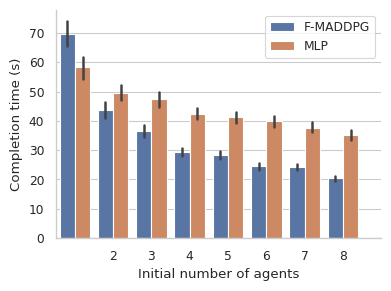

In [21]:
fig, ax = plt.subplots(figsize=(4.0, 3.0))
sns.barplot(
    data=completion_episodes, x="num_agents", y="completion_time",
    hue="condition", hue_order=["F-MADDPG", "MLP"],
    errorbar=("ci", 95), ax=ax,
)
ax.set(xlabel="Initial number of agents", ylabel="Completion time (s)", xticks=range(1, 9))
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading Figure 3.** Both policies achieve high final success rates. The largest success-rate difference occurs with one agent, where F-MADDPG is 6.6 percentage points below the MLP baseline. Across the full 2,000-episode evaluation, F-MADDPG reduces mean completion time by 7.2 seconds; the paired-success panel shows that its completion-time advantage is concentrated in multi-agent settings. Together with Figure 2, these results support the paper's claims that F-MADDPG learns faster and completes missions faster on average, rather than claiming that only the flexible architecture can tolerate failures.

In [22]:
architecture_grid = (architecture_episodes
  .groupby(['num_agents', 'num_sensors', 'condition'])[['success_percent', 'completion_time']]
  .agg(['mean', 'std'])
  .reset_index()
  .rename(columns={"success_percent": "Success Rate", "completion_time": "Completion Time", "num_agents": "Number of Agents", "num_sensors": "Number of Sensors"}))
architecture_grid


Number of Agents Number of Sensors     condition Success Rate             \
                                                             mean        std   
0                  1                 1  Flex Encoder        100.0   0.000000   
1                  1                 1           MLP        100.0   0.000000   
2                  1                 2  Flex Encoder        100.0   0.000000   
3                  1                 2           MLP        100.0   0.000000   
4                  1                 3  Flex Encoder         90.0  31.622777   
..               ...               ...           ...          ...        ...   
571                8                34           MLP        100.0   0.000000   
572                8                35  Flex Encoder        100.0   0.000000   
573                8                35           MLP        100.0   0.000000   
574                8                36  Flex Encoder        100.0   0.000000   
575                8                36           MLP        100.0   0.000000   

    Completion Time              
               mean         std  
0          7.800000    1.751190  
1          7.800000    1.751190  
2         12.400000    3.847077  
3         12.000000    3.741657  
4         71.200000  150.900114  
..              ...         ...  
571       61.000000   18.384776  
572       28.909091    5.009083  
573       60.909091   10.054398  
574       30.000000    4.898979  
575       58.000000    8.602325  

[576 rows x 7 columns]

<Axes: xlabel='Number of Sensors', ylabel='Number of Agents'>

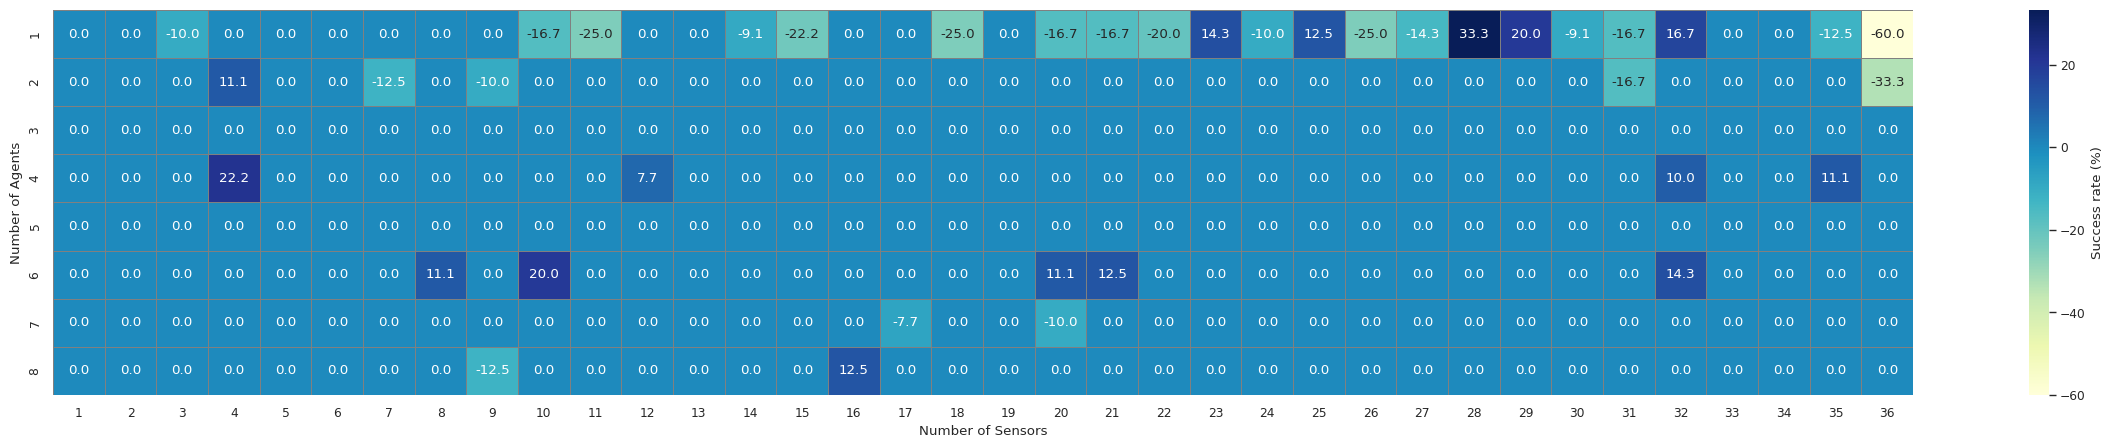

In [23]:
fix, ax = plt.subplots(figsize=(30, 5.0))

flex_grid = architecture_grid[architecture_grid['condition'] == 'Flex Encoder'].pivot(index="Number of Agents", columns="Number of Sensors", values=("Success Rate", "mean"))
mlp_grid = architecture_grid[architecture_grid['condition'] == 'MLP'].pivot(index="Number of Agents", columns="Number of Sensors", values=("Success Rate", "mean"))

sns.heatmap(
    data=flex_grid - mlp_grid,
    annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Success rate (%)"},
    linewidths=0.5, linecolor="gray", ax=ax
)

In [24]:
overall_summary_per_agent = architecture_episodes.groupby(["num_agents", "condition"])[["success_percent", "completion_time"]].agg("mean")
overall_summary_per_agent

success_percent  completion_time
num_agents condition                                     
1          Flex Encoder        89.516129       115.298387
           MLP                 95.967742        76.870968
2          Flex Encoder        98.275862        51.370690
           MLP                 99.568966        51.500000
3          Flex Encoder       100.000000        36.588710
           MLP                100.000000        47.346774
4          Flex Encoder       100.000000        29.289796
           MLP                 97.959184        51.697959
5          Flex Encoder       100.000000        28.206642
           MLP                100.000000        41.180812
6          Flex Encoder       100.000000        24.583658
           MLP                 98.054475        48.747082
7          Flex Encoder        99.236641        27.832061
           MLP                100.000000        37.625954
8          Flex Encoder        99.578059        22.371308
           MLP                 99.578059        36.978903

In [25]:
overall_summary = architecture_episodes.groupby("condition")["completion_time"].agg("mean")
overall_summary

condition
Flex Encoder    41.659
MLP             48.865
Name: completion_time, dtype: float64

# Experiment 4 - Larger populations
**Research question.** Does F-MADDPG generalize to larger population sizes?

We apply the `5_deathless` policy, trained with [1, 8] agents to increasingly larger populations and measure it's success rate and completion time.

In [4]:
larger_population_chunks = []
for population in POPULATION_TRIALS:
    for model in ("5_deathless", "6_mlp"):
        base_model = RUNS[model].final_model()
        episodes = base_model.evaluate(
            FINAL_EVAL_EPISODES,
            seed=SAMPLING_EVAL_SEED,
            num_workers=4,
            config_overrides={"environment": {"death_scheduler": {"type": "stochastic", "probability": 0.0}, "min_num_agents": population, "max_num_agents": population}},
        ).assign(
            population=population,
            condition="F-MADDPG" if model == "5_deathless" else "MLP"
        )
        larger_population_chunks.append(episodes)

larger_population_episodes = pd.concat(larger_population_chunks, ignore_index=True).assign(success_percent=lambda data: data["all_collected"].astype(float) * 100)

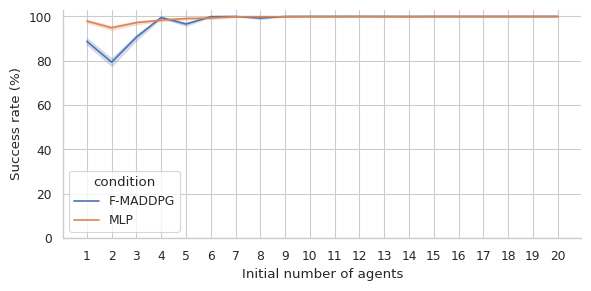

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.0))
sns.lineplot(
    data=larger_population_episodes,
    x="population",
    y="success_percent",
    errorbar=("ci", 95),
    ax=ax,
    hue="condition",
)
ax.set(xlabel="Initial number of agents", ylabel="Success rate (%)", ylim=(0, 103), xticks=POPULATION_TRIALS)
fig.tight_layout()

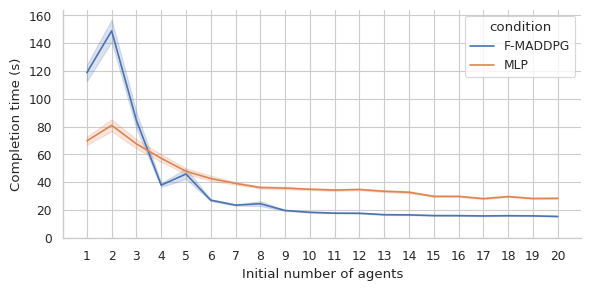

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.0))
sns.lineplot(
    data=larger_population_episodes,
    x="population",
    y="completion_time",
    errorbar=("ci", 95),
    ax=ax,
    hue="condition"
)
ax.set(xlabel="Initial number of agents", ylabel="Completion time (s)", ylim=(0, None), xticks=POPULATION_TRIALS)
fig.tight_layout()